Name: Hriday Juneja

Student number: 991602467

**Project 7:** Wine Quality Data Set (Red wine)

Task: Regression

Target: Alcohol

# Regression - PyCaret 4.0: Predicting the Alcohol Content of Red Wine

Predict a continuous target. In this research project we use **PyCaret 4.0** to predict the **alcohol** content (% by volume) of red wine from its other physicochemical properties.

In [1]:
%%capture
!pip install --pre "pycaret==4.0.0a8" -q

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
import pycaret
print("PyCaret", pycaret.__version__)

PyCaret 4.0.0a8


## 1. Load data

In [3]:
# Load the red wine dataset (delimiter is ';')
url_red = "https://raw.githubusercontent.com/tofighi/MachineLearning/master/datasets/winequality-red.csv"
df_wine = pd.read_csv(url_red, sep=";")
print(f"Red Wine Dataset Shape: {df_wine.shape}")
df_wine.head()

Red Wine Dataset Shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 2. Exploratory Data Analysis (EDA)

Before training, we check the data types, missing values, duplicate rows, and how each feature is related to `alcohol`.

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

--- Target Summary (alcohol) ---
count    1599.0000
mean       10.4230
std         1.0657
min         8.

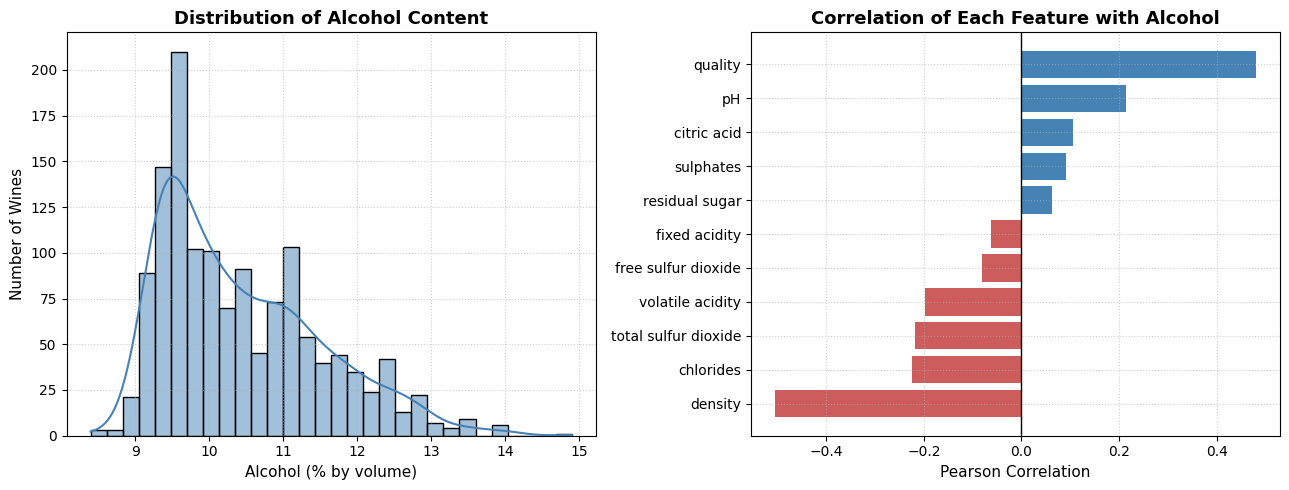

In [4]:
print("--- Dataset Info ---")
df_wine.info()

print("\n--- Target Summary (alcohol) ---")
print(df_wine["alcohol"].describe().round(4))

print(f"\nTotal Missing Values: {df_wine.isnull().sum().sum()}")
print(f"Duplicate Rows: {df_wine.duplicated().sum()}")

# Remove duplicate rows so the same wine cannot appear in both train and test sets
df_wine = df_wine.drop_duplicates().reset_index(drop=True)
print(f"Shape after removing duplicates: {df_wine.shape}")

# Correlation of each feature with alcohol
corr_alcohol = df_wine.corr()["alcohol"].drop("alcohol").sort_values()
print("\n--- Correlation with alcohol ---")
print(corr_alcohol.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Distribution of the target
sns.histplot(df_wine["alcohol"], bins=30, kde=True, color="steelblue", ax=axes[0])
axes[0].set_title("Distribution of Alcohol Content", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Alcohol (% by volume)", fontsize=11)
axes[0].set_ylabel("Number of Wines", fontsize=11)
axes[0].grid(True, linestyle=":", alpha=0.6)

# Plot 2: Correlation of each feature with alcohol
colors = ["indianred" if c < 0 else "steelblue" for c in corr_alcohol]
axes[1].barh(corr_alcohol.index, corr_alcohol.values, color=colors)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("Correlation of Each Feature with Alcohol", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Pearson Correlation", fontsize=11)
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

## 3. Fit an experiment

We use a 70% Train / 30% Test split (PyCaret default), 10-fold cross-validation, and `normalize=True` so distance-based models (SVM, k-NN) are not dominated by features with large scales such as `total sulfur dioxide`.

In [5]:
from pycaret.tasks import RegressionExperiment

exp = RegressionExperiment(target="alcohol", session_id=42, normalize=True, n_jobs=1).fit(df_wine)
print(f"X_train shape: {exp.X_train.shape} | X_test shape: {exp.X_test.shape}")

X_train shape: (951, 11) | X_test shape: (408, 11)


## 4. Compare models

In [6]:
%%capture
# Train all available regressors with 10-fold CV and sort them by RMSE (lower is better)
result = exp.compare_models(sort="RMSE")

In [7]:
result.leaderboard

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE
0,svm,0.3892,0.2885,0.5302,0.7536,0.0451,0.0
1,lightgbm,0.3975,0.3035,0.5440,0.7395,0.0465,0.0
2,gbr,0.4111,0.3042,0.5469,0.7362,0.0467,0.0
3,et,0.4204,0.3371,0.5731,0.7116,0.0490,0.0
4,rf,0.4268,0.3428,0.5786,0.7049,0.0495,0.0
5,lr,0.4482,0.3453,0.5818,0.6997,0.0502,0.0
6,ridge,0.4483,0.3453,0.5818,0.6998,0.0502,0.0
7,br,0.4484,0.3454,0.5819,0.6997,0.0502,0.0
8,ard,0.4487,0.3465,0.5828,0.6988,0.0503,0.0
9,huber,0.4434,0.3501,0.5859,0.6951,0.0506,0.0


## 5. Tune the best model

We first create the best model from the leaderboard, then tune its hyperparameters. PyCaret's default search grid is compared with a custom grid (`param_grid`).

In [8]:
# 1. Create the best model from compare_models
best_id = result.leaderboard.iloc[0]["Model"]
best = exp.create_model(best_id)
print(f"Best Model: {best_id}")
print(best.metrics.loc[["Mean", "Std"]])

# 2. Tune with PyCaret's default grid
tuned_default = exp.tune_model(best.pipeline, n_iter=20, optimize="RMSE")
print(f"\nDefault Grid Best Params: {tuned_default.best_params}")

# 3. Tune with a custom grid
param_grid = {"C": [0.1, 0.5, 1, 2, 5, 10, 20, 50],
              "epsilon": [0.01, 0.05, 0.1, 0.2, 0.5],
              "gamma": ["scale", 0.01, 0.05, 0.1, 0.2]}
tuned = exp.tune_model(best.pipeline, n_iter=50, custom_grid=param_grid, optimize="RMSE")
print(f"Custom Grid Best Params:  {tuned.best_params}")

# 4. Compare 10-fold CV results
cv_compare = pd.DataFrame({
    "Untuned": best.metrics.loc["Mean"],
    "Tuned (default grid)": tuned_default.metrics.loc["Mean"],
    "Tuned (custom grid)": tuned.metrics.loc["Mean"]
}).T
print("\n--- 10-Fold CV Mean Metrics ---")
print(cv_compare[["MAE", "RMSE", "R2"]].round(4))

Best Model: svm
         MAE     MSE    RMSE      R2   RMSLE  MAPE
Mean  0.3892  0.2885  0.5302  0.7536  0.0451   0.0
Std   0.0511  0.0989  0.0854  0.0523  0.0066   0.0

Default Grid Best Params: {'shrinking': False, 'epsilon': 1.1, 'C': 8.697000000000001}
Custom Grid Best Params:  {'gamma': 0.01, 'epsilon': 0.1, 'C': 50}

--- 10-Fold CV Mean Metrics ---
                         MAE    RMSE      R2
Untuned               0.3892  0.5302  0.7536
Tuned (default grid)  0.5471  0.6802  0.5938
Tuned (custom grid)   0.3704  0.5024  0.7764


## 6. Predict on the test set

In [9]:
preds = exp.predict_model(tuned.pipeline)
print("Tuned Model Metrics on Test Set:")
print(preds.metrics.to_string(index=False))

preds.predictions[["alcohol", "prediction_label"]].head()

Tuned Model Metrics on Test Set:
Model    MAE    MSE  RMSE     R2  RMSLE  MAPE
  SVR 0.4165 0.2949 0.543 0.7458 0.0467     0


,alcohol,prediction_label
51,9.5,9.667704
1100,10.9,10.410768
1312,11.2,11.379588
514,9.0,9.890637
1074,11.2,11.235785


## 7. Evaluate the model

We plot predicted vs. actual alcohol, the residuals (Actual − Predicted), and the permutation importance of each feature on the test set.

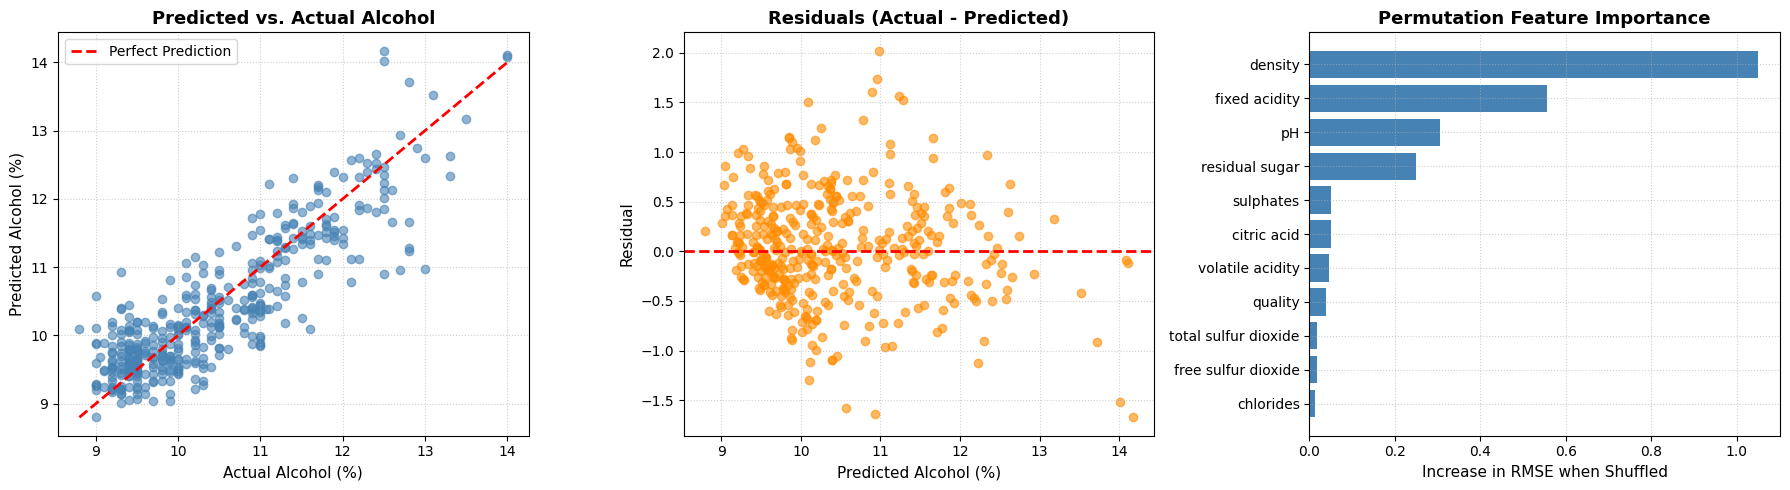

--- Permutation Feature Importance (Increase in RMSE) ---
density                 1.0493
fixed acidity           0.5559
pH                      0.3067
residual sugar          0.2484
sulphates               0.0495
citric acid             0.0494
volatile acidity        0.0459
quality                 0.0400
total sulfur dioxide    0.0186
free sulfur dioxide     0.0183
chlorides               0.0132
dtype: float64


In [10]:
from sklearn.inspection import permutation_importance

y_test = preds.predictions["alcohol"]
y_pred = preds.predictions["prediction_label"]
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Predicted vs. Actual
axes[0].scatter(y_test, y_pred, alpha=0.6, color="steelblue")
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2, label="Perfect Prediction")
axes[0].set_title("Predicted vs. Actual Alcohol", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Actual Alcohol (%)", fontsize=11)
axes[0].set_ylabel("Predicted Alcohol (%)", fontsize=11)
axes[0].legend(fontsize=10)
axes[0].grid(True, linestyle=":", alpha=0.6)

# Plot 2: Residuals vs. Predicted
axes[1].scatter(y_pred, residuals, alpha=0.6, color="darkorange")
axes[1].axhline(0, color="red", linestyle="--", lw=2)
axes[1].set_title("Residuals (Actual - Predicted)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Predicted Alcohol (%)", fontsize=11)
axes[1].set_ylabel("Residual", fontsize=11)
axes[1].grid(True, linestyle=":", alpha=0.6)

# Plot 3: Permutation importance (increase in RMSE when a feature is shuffled)
perm = permutation_importance(tuned.pipeline, exp.X_test, exp.y_test, n_repeats=10,
                              random_state=42, scoring="neg_root_mean_squared_error")
importances = pd.Series(perm.importances_mean, index=exp.X_test.columns).sort_values()
axes[2].barh(importances.index, importances.values, color="steelblue")
axes[2].set_title("Permutation Feature Importance", fontsize=13, fontweight="bold")
axes[2].set_xlabel("Increase in RMSE when Shuffled", fontsize=11)
axes[2].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

print("--- Permutation Feature Importance (Increase in RMSE) ---")
print(importances.sort_values(ascending=False).round(4))

## 8. Finalize and persist

`finalize_model` re-trains the tuned pipeline on the full dataset (train + test) before saving it.

In [11]:
from pycaret import save_model

final = exp.finalize_model(tuned.pipeline)
save_model(final.pipeline, "wine_alcohol_regressor")

PosixPath('/content/wine_alcohol_regressor.pkl')

## 9. Conclusions

* **Data:** The red wine dataset has no missing values, but it has 240 duplicate rows. We removed them so the same wine cannot appear in both the train and test sets, which left 1,359 wines (951 train, 408 test).

* **Best model:** Based on the 10-fold cross-validation leaderboard, Support Vector Regression (`svm`) had the lowest RMSE (0.5302), ahead of LightGBM (0.5440) and Gradient Boosting (0.5469). Tuning with PyCaret's default grid made it worse (RMSE 0.6802), because that grid only tries `epsilon` values of 1.1 or more. With our custom grid, the best parameters were `C = 50`, `gamma = 0.01` and `epsilon = 0.1`, and the CV RMSE dropped to 0.5024 (R² = 0.7764).

* **Test performance:** On the test set, the tuned model has an RMSE of 0.5430, an MAE of 0.4165 and an R² of 0.7458. This means a typical prediction is off by about 0.4 to 0.5% alcohol, and the model explains about 75% of the variation in alcohol content. In the predicted vs. actual plot, the model slightly over-predicts wines with low alcohol and under-predicts wines with very high alcohol, since there are few wines above 13% to learn from.

* **Most important features:** `density` is by far the most important feature, followed by `fixed acidity`, `pH` and `residual sugar`. This matches the chemistry, because alcohol is lighter than water and lowers the density of the wine, while sugar and acids raise it. `quality` has a correlation of 0.48 with alcohol, but it adds little once density is known, so its permutation importance is small.